In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import OneHotEncoder , LabelEncoder , StandardScaler
from sklearn.metrics import silhouette_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [76]:
data = pd.read_excel('/content/Online Retail.xlsx')

In [78]:
df = data
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [79]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [83]:
df.isnull().sum().sum()

np.int64(136534)

In [84]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [85]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


In [86]:
df = df.dropna(subset=["CustomerID"]).copy()
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")].copy()
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

print("Transactions after cleaning:", len(df))

Transactions after cleaning: 397884


In [87]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


In [89]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

In [90]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [93]:
df.head(0)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice


In [94]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
customers = df.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()
customers["Recency"] = (reference_date - customers["LastPurchase"]).dt.days
customers = customers[["CustomerID", "Recency", "Frequency", "Monetary"]]
customers.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [95]:
customers.shape

(4338, 4)

In [96]:
customers.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,4338.0,15300.408022,1721.808492,12346.00,13813.250,15299.500,16778.75,18287.00
Recency,4338.0,92.536422,100.014169,1.00,18.000,51.000,142.00,374.00
Frequency,4338.0,4.272015,7.697998,1.00,1.000,2.000,5.00,209.00
Monetary,4338.0,2054.266460,8989.230441,3.75,307.415,674.485,1661.74,280206.02


<Axes: >

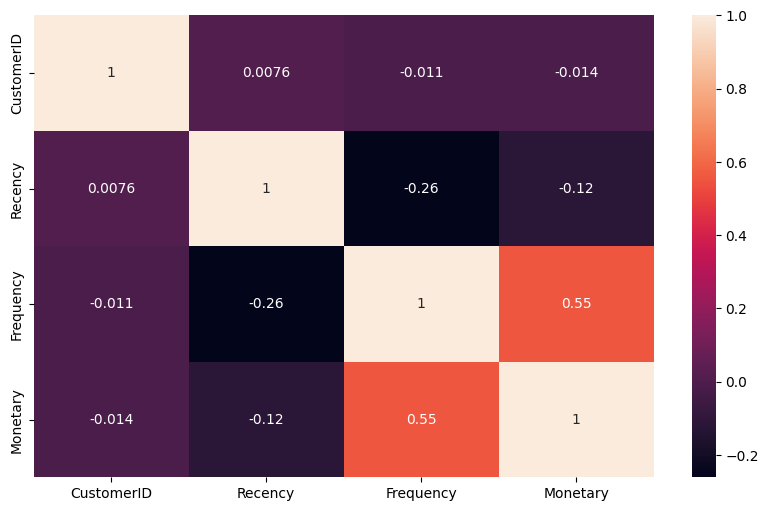

In [97]:
plt.figure(figsize=(10, 6))
sns.heatmap(customers.corr(), annot=True)

In [100]:
X = customers[["Recency", "Frequency", "Monetary"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (4338, 3)


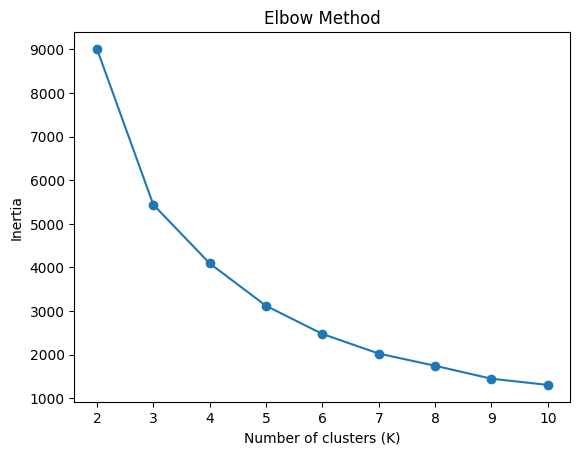

In [102]:
inertia = []
k_values = range(2, 11)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)
plt.plot(list(k_values), inertia, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [103]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
customers["Cluster"] = kmeans.fit_predict(X_scaled)
customers.head(10)

,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346.0,326,1,77183.60,0
1,12347.0,2,7,4310.00,1
2,12348.0,75,4,1797.24,1
3,12349.0,19,1,1757.55,1
4,12350.0,310,1,334.40,0
5,12352.0,36,8,2506.04,1
6,12353.0,204,1,89.00,0
7,12354.0,232,1,1079.40,0
8,12355.0,214,1,459.40,0
9,12356.0,23,3,2811.43,1


In [118]:
customers['Cluster'].value_counts().sort_index()

,count
Cluster,
0,1082
1,3230
2,26


In [110]:
summary = customers.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(2)
summary["Customers"] = customers.groupby("Cluster").size()
summary

,Recency,Frequency,Monetary,Customers
Cluster,,,,
0,247.11,1.58,631.42,1082
1,41.45,4.67,1855.94,3230
2,6.04,66.42,85904.35,26


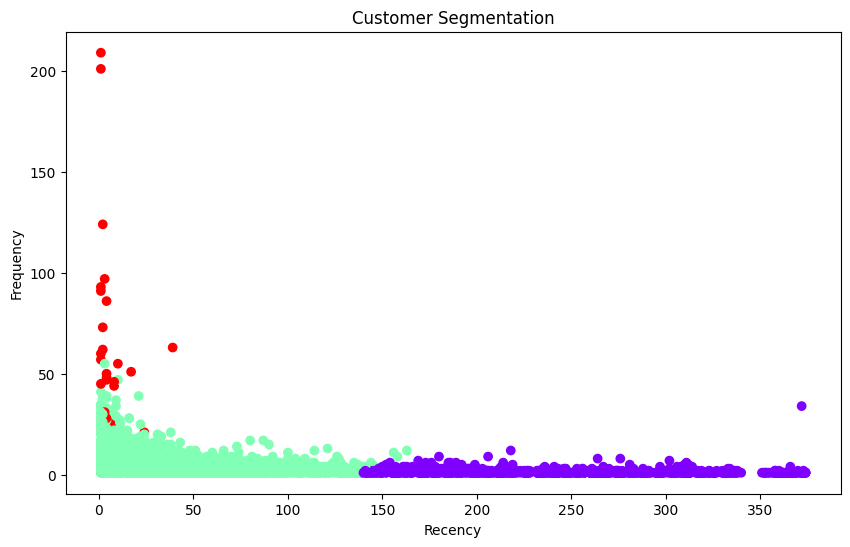

In [111]:
plt.figure(figsize=(10, 6))
plt.scatter(customers["Recency"], customers["Frequency"], c=customers["Cluster"], cmap="rainbow")
plt.xlabel("Recency")
plt.ylabel("Frequency")
plt.title("Customer Segmentation")
plt.show()

In [114]:
# plt.figure(figsize=(10, 6))
# plt.scatter(customers["Monetary"], customers["Frequency"], c=customers["Cluster"], cmap="rainbow")
# plt.xlabel("Monetary")
# plt.ylabel("Frequency")
# plt.title("Customer Segmentation")
# plt.show()

In [119]:
kmeans.cluster_centers_

array([[ 1.54565781, -0.34945057, -0.15830123],
       [-0.51080894,  0.05206378, -0.02206496],
       [-0.86495677,  8.07459659,  9.32891329]])

In [123]:
scaled_centroids = kmeans.cluster_centers_
centroids_unscaled = scaler.inverse_transform(scaled_centroids)

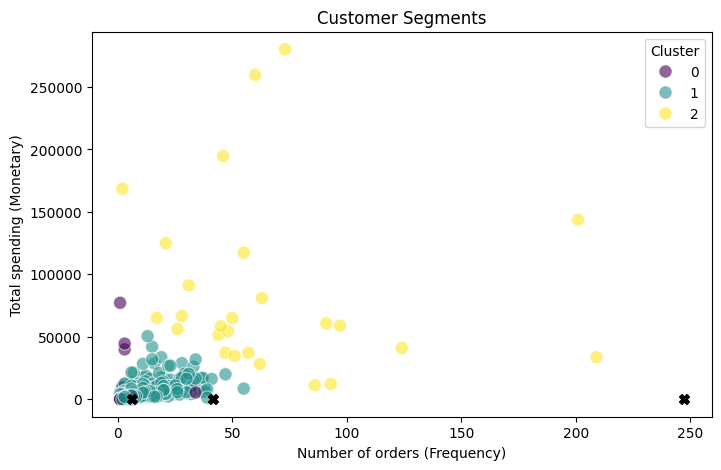

In [128]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=customers,x = customers["Frequency"], y = customers["Monetary"], hue=customers["Cluster"], palette="viridis", alpha=0.6, s=90)
plt.scatter(centroids_unscaled[:, 0], centroids_unscaled[:, 1], color='black', marker='X', s=50, label='Centroids')
plt.xlabel("Number of orders (Frequency)")
plt.ylabel("Total spending (Monetary)")
plt.title("Customer Segments")
plt.show()